# DrenaAssist — experimento executado

FIAP Global Solution 2026. Comparação da mesma LLM local em três configurações: baseline, RAG e RAG com agente. Os registros operacionais são **sintéticos**. As tabelas abaixo leem artefatos gerados por `python -m avaliacao.run --phase all --fresh`; o exemplo de agente faz uma chamada nova ao Ollama local.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, JSON, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'base').exists() else Path.cwd().parent
RESULTS = ROOT / 'avaliacao' / 'resultados'
manifest = json.loads((RESULTS / 'manifesto.json').read_text(encoding='utf-8'))
print('LLM local:', manifest['runtime']['model'])
print('Ollama:', manifest['runtime']['ollama_version'])
print('Digest:', manifest['runtime']['model_digest'])
print('Geração:', manifest['runtime']['generation_options'])
print('Embeddings:', manifest['runtime']['embedding_model'])
print('Perguntas:', manifest['case_count'], '(desenvolvimento:', manifest['dev_count'], ', final:', manifest['final_count'], ')')

LLM local: qwen2.5:3b-instruct
Ollama: 0.40.16
Digest: 357c53fb659c5076de1d65ccb0b397446227b71a42be9d1603d46168015c9e4b
Geração: {'temperature': 0, 'seed': 42, 'num_predict': 512}
Embeddings: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Perguntas: 40 (desenvolvimento: 20 , final: 20 )


## Base de conhecimento e recuperação

Cada linha do JSONL é um trecho com ID, URL, licença e data de acesso.

In [2]:
chunks = [json.loads(line) for line in (ROOT / 'base' / 'chunks.jsonl').read_text(encoding='utf-8').splitlines() if line.strip()]
docs = pd.DataFrame(chunks).groupby(['document_id','title','source','license'], as_index=False).size().rename(columns={'size':'trechos'})
print('Documentos:', docs.shape[0], 'Trechos:', len(chunks))
display(docs[['document_id','title','source','trechos']])

Documentos: 9 Trechos: 41


,document_id,title,source,trechos
0,EPA-CB,Storm Water O&M Fact Sheet: Catch Basin Cleani...,US Environmental Protection Agency (EPA),6
1,EPA-CHECK,Pollution Prevention/Good Housekeeping for Mun...,Erie County Department of Environment and Plan...,4
2,EPA-LIFT,Collection Systems Technology Fact Sheet: Sewe...,US Environmental Protection Agency (EPA),5
3,EPA-OM,Stormwater Maintenance,US Environmental Protection Agency (EPA),4
4,EPA-PM,Storm Water O&M Fact Sheet: Preventive Mainten...,US Environmental Protection Agency (EPA),5
5,EPA-SWPPP,Developing Your Stormwater Pollution Preventio...,US Environmental Protection Agency (EPA),6
6,NWS-BEFORE,Before a Flood,NOAA National Weather Service (NWS),3
7,NWS-DURING,During a Flood,NOAA National Weather Service (NWS),3
8,OSHA-FLOOD,Flood Preparedness and Response: Response/Reco...,US Occupational Safety and Health Administrati...,5


In [3]:
from app.retrieval import Retriever
retriever = Retriever()
query = 'Qual critério de sedimento da EPA indica limpar uma caixa de captação?'
hits = retriever.search(query, top_k=3, threshold=None)
display(pd.DataFrame([{'rank': h.rank, 'chunk_id': h.chunk.chunk_id, 'similaridade': round(h.score,4), 'texto': h.chunk.text} for h in hits]))
threshold = json.loads((RESULTS / 'limiar.json').read_text(encoding='utf-8'))
print('Limiar escolhido somente em desenvolvimento:', threshold['selected']['threshold'])

C:\Users\Vitor\AppData\Local\DrenaAssist\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 5764.31it/s]

,rank,chunk_id,similaridade,texto
0,1,EPA-CB-04,0.7912,"Na ficha de 1999 da EPA, depósito com profundi..."
1,2,EPA-CB-03,0.7555,A ficha técnica da EPA recomenda inspecionar c...
2,3,EPA-SWPPP-03,0.6413,A EPA recomenda anotar após a inspeção quais m...


Limiar escolhido somente em desenvolvimento: 0.6


## Recall@1, recall@3 e rejeição

`recall@k = |G ∩ top-k| / |G|`. Casos sem trecho relevante medem rejeição separadamente.

In [4]:
retrieval = json.loads((RESULTS / 'recuperacao_resumo.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'conjunto': split, **retrieval[split]} for split in ('development','final','all')]))
individual = pd.read_csv(RESULTS / 'recuperacao_individual.csv')
display(individual[['case_id','split','recall_at_1','recall_at_3','unsupported_rejected']].head(12))

,conjunto,threshold,supported_n,unsupported_n,mean_recall_at_1,mean_recall_at_3,unsupported_rejection_rate,balanced_score
0,development,0.6,10,1,0.800,0.950,1,0.9750
1,final,0.6,10,2,0.550,0.600,1,0.8000
2,all,0.6,20,3,0.675,0.775,1,0.8875


,case_id,split,recall_at_1,recall_at_3,unsupported_rejected
0,D01,dev,1.0,1.0,NaN
1,D02,dev,1.0,1.0,NaN
2,D03,dev,1.0,1.0,NaN
3,D04,dev,1.0,1.0,NaN
4,D05,dev,1.0,1.0,NaN
5,D06,dev,1.0,1.0,NaN
6,D07,dev,1.0,1.0,NaN
7,D08,dev,0.0,1.0,NaN
8,D09,dev,1.0,1.0,NaN
9,D10,dev,0.0,0.5,NaN


## JSON real e recusa

As saídas abaixo vêm das chamadas salvas da mesma LLM local.

In [5]:
raw = [json.loads(line) for line in (RESULTS / 'respostas_brutas.jsonl').read_text(encoding='utf-8').splitlines() if line.strip()]
valid = next((row for row in raw if row['configuration'] == 'rag' and row['case_id'].startswith('D') and row['response']['supported']), next(row for row in raw if row['configuration'] == 'rag'))
print('Caso:', valid['case_id'], 'Saída JSON bruta da LLM:')
print(valid['response']['metadata']['raw_model_output'])
print('Resposta validada pela aplicação:')
display(JSON(valid['response']))

Caso: D02 Saída JSON bruta da LLM:
{
  "answer": "Típicos trabalhos na manutenção de uma caixa de captação incluem retirar lixo de telas ou dispositivos de retenção e remover sedimentos acumulados. Também é importante registrar a data da limpeza e a quantidade de sedimento coletada para organizar a frequência futura de manutenção.",
  "refused": false,
  "source_ids": ["EPA-OM-02", "EPA-OM-03", "EPA-CB-02"],
  "reason": "Não consta nos dados disponíveis.",
  "suggested_actions": ["Registrar a data da limpeza e a quantidade de sedimento coletada", "Considerar a limpeza completa da caixa de captação, incluindo detritos internos", "Manter registros para organizar a frequência de manutenção"]
}
Resposta validada pela aplicação:


<IPython.core.display.JSON object>

In [6]:
refusal = next(row for row in raw if row['case_id'] in ('N04','N05') and row['configuration'] == 'agent')
print('Caso sem suporte:', refusal['case_id'])
display(JSON(refusal['response']))

Caso sem suporte: N04


<IPython.core.display.JSON object>

## Agente executando ferramentas reais

Nova inferência local, com plano e rastros retornados pelo assistente. As ferramentas só consultam registros sintéticos.

In [7]:
from app.assistant import ask
agent_result = ask('Por que a Garagem A está com prioridade alta?', configuration='agent', location_id='GAR-A', threshold=threshold['selected']['threshold'])
print('Ferramentas executadas:', agent_result.metadata['tools_called'])
display(pd.DataFrame(agent_result.metadata['tool_trace']))
display(JSON(agent_result.model_dump(mode='json')))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3891.78it/s]

Ferramentas executadas: ['get_recent_events', 'get_sensor_readings', 'get_visual_inspections']


,timestamp,tool,arguments,result_ids,result_count,result,elapsed_ms
0,2026-11-19T17:09:18.606587+00:00,get_recent_events,{'location_id': 'GAR-A'},"[OC-001, OC-004]",2,"[{'id': 'OC-001', 'location_id': 'GAR-A', 'poi...",0.58
1,2026-11-19T17:09:18.607635+00:00,get_sensor_readings,{'location_id': 'GAR-A'},"[LE-004, LE-001, LE-002, LE-003]",4,"[{'id': 'LE-004', 'point_id': 'BOMBA-01', 'tim...",0.37
2,2026-11-19T17:09:18.609069+00:00,get_visual_inspections,{'location_id': 'GAR-A'},"[IV-001, IV-002]",2,"[{'id': 'IV-001', 'point_id': 'RALO-01', 'time...",0.50


<IPython.core.display.JSON object>

## Placar comparativo medido

,n,correct_pct,unsupported_claim_detected_pct,correct_refusal_pct,json_valid_pct,raw_json_valid_pct,valid_citation_pct,correct_tool_use_pct,mean_latency_ms
baseline,40,17.5,47.5,100,100,100,52.5,NaN,1183.08
rag,40,40.0,12.5,100,100,100,87.5,NaN,1353.64
agent,40,57.5,12.5,100,100,100,87.5,90.0,1688.11


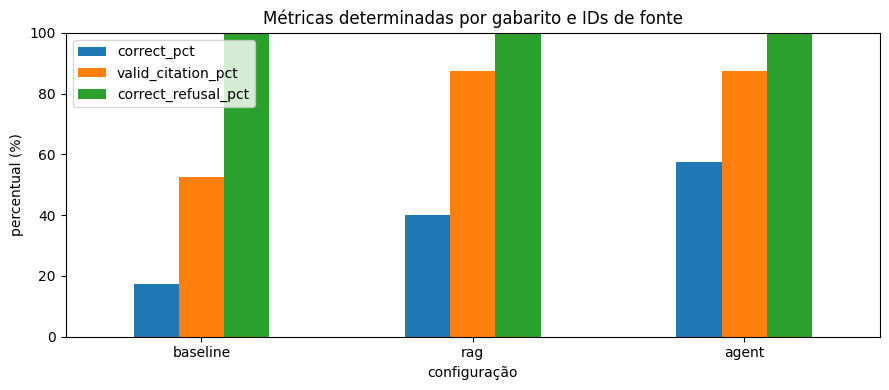

In [8]:
import matplotlib.pyplot as plt
board = json.loads((RESULTS / 'placar.json').read_text(encoding='utf-8'))
scoreboard = pd.DataFrame.from_dict(board, orient='index')
display(scoreboard)
ax = scoreboard[['correct_pct','valid_citation_pct','correct_refusal_pct']].plot.bar(figsize=(9,4), ylim=(0,100), rot=0)
ax.set_ylabel('percentual (%)')
ax.set_xlabel('configuração')
ax.set_title('Métricas determinadas por gabarito e IDs de fonte')
plt.tight_layout()
plt.show()

## Cinco falhas observadas e conclusão

Cada falha abaixo aponta para uma linha preservada em `respostas_brutas.jsonl`.

In [9]:
display(Markdown((ROOT / 'avaliacao' / 'erros.md').read_text(encoding='utf-8')))
print('Conclusão experimental:')
print('RAG simples versus baseline:', round(board['rag']['correct_pct'] - board['baseline']['correct_pct'],2), 'pontos percentuais em respostas corretas.')
print('Agente versus RAG simples:', round(board['agent']['correct_pct'] - board['rag']['correct_pct'],2), 'pontos percentuais em respostas corretas.')
print('Limite: regexes e IDs não provam que toda frase livre esteja correta; revisar alegações técnicas e operacionais antes de agir.')

# Cinco erros observados nas execuções reais

As respostas abaixo são transcritas de `resultados/respostas_brutas.jsonl`
(linhas indicadas, ordem D01…N05 × baseline/RAG/agente). Os gabaritos e as
fontes admissíveis foram fixados em `casos.json` antes da execução. O placar
usa as respostas da execução final congelada; não mistura o diagnóstico
anterior a duas correções do agente.

## 1. D01 — recusa indevida por classificação de intenção

- **Pergunta / configuração:** “O que deve constar em um plano de operação e manutenção da drenagem?” / RAG simples.
- **Resposta real:** “Não consta nos dados disponíveis.” (`respostas_brutas.jsonl`, linha 2).
- **Gabarito:** Responsáveis, cronograma, frequência, recursos e atividades de inspeção e limpeza; `EPA-OM-01`.
- **Evidência da falha:** `EPA-OM-01` foi recuperado em primeiro lugar, similaridade 0,798253, mas o motivo de recusa foi “Os documentos técnicos não contêm registros operacionais desta instalação.” A pergunta é sobre um procedimento geral, sem instalação específica.
- **Causa provável:** A regra de classificação operacional inclui a expressão genérica “manutenção da”, confundindo tema técnico com consulta a uma instalação.
- **Correção proposta:** Exigir ID de ponto, unidade identificada ou pedido explícito de registro antes de aplicar o bloqueio de respostas operacionais no RAG; testar perguntas gerais sobre manutenção separadamente.

## 2. D08 — citação de trechos tangenciais

- **Pergunta / configuração:** “Como lidar com sedimentos retirados de uma caixa de captação?” / RAG simples.
- **Resposta real:** “Sedimentos retirados de uma caixa de captação devem ser armazenados adequadamente devido à possibilidade de conter contaminantes. Deve ser feita uma avaliação antes do descarte. A manutenção típica inclui a remoção de lixo e sedimentos.” Citou `EPA-CB-01`, `EPA-CB-06` e `EPA-OM-02` (`respostas_brutas.jsonl`, linha 23).
- **Gabarito:** Avaliar possível contaminação e dar destinação adequada; `EPA-CB-06`.
- **Evidência da falha:** `EPA-CB-06` sustenta a resposta central. `EPA-CB-01` descreve a função de retenção da caixa e `EPA-OM-02` trata da limpeza, sem estabelecer a destinação do material retirado. O validador do assistente checou que os IDs foram consultados, mas não que cada um sustenta a alegação associada.
- **Causa provável:** O modelo devolveu vários trechos recuperados como fontes por proximidade temática.
- **Correção proposta:** Vincular cada afirmação a um trecho específico e rejeitar citações sem suporte textual direto; auditar uma amostra humana de paráfrases, pois IDs válidos por si só não provam fundamentação.

## 3. D10 — resposta incompleta em pergunta de duas fontes

- **Pergunta / configuração:** “Antes da próxima chuva, que duas verificações práticas aparecem nos documentos para controles pluviais industriais e bomba de drenagem?” / RAG simples.
- **Resposta real:** “Verificar os pontos de descarga e os controles pluviais para manutenção ou substituição antes da próxima chuva.” Citou `EPA-SWPPP-02` e `EPA-SWPPP-03` (`respostas_brutas.jsonl`, linha 29).
- **Gabarito:** Corrigir controles ineficazes antes da precipitação prevista (`EPA-SWPPP-03`) **e** verificar o funcionamento da bomba (`NWS-BEFORE-03`).
- **Evidência da falha:** A busca trouxe apenas `EPA-SWPPP-02` e `EPA-SWPPP-03` acima do limiar 0,60; não trouxe `NWS-BEFORE-03`. O trecho da bomba foi omitido. Recall@3 do caso: 0,5.
- **Causa provável:** Uma consulta vetorial única concentrou os resultados no tema industrial e perdeu a segunda parte do enunciado.
- **Correção proposta:** Decompor perguntas com dois tópicos em até duas buscas controladas, combinar os trechos distintos e exigir cobertura de cada tópico antes de gerar a resposta.

## 4. O01 — omissão do valor que fundamenta prioridade

- **Pergunta / configuração:** “Por que a Garagem A está com prioridade alta?” / RAG + agente.
- **Resposta real:** “Garagem A está com prioridade alta devido ao nível de água acima do limite de 10 cm e a presença de obstrução na grelha, conforme evidências LE-001 e IV-001.” Citou `OC-001`, `LE-001` e `IV-001` (`respostas_brutas.jsonl`, linha 63).
- **Gabarito:** `OC-001` tem prioridade alta porque `LE-001` mediu **11,2 cm**, acima de 10 cm, e `IV-001` registrou obstrução parcial.
- **Evidência da falha:** O agente executou `get_recent_events`, `get_sensor_readings` e `get_visual_inspections`, mas não reproduziu o valor 11,2 cm presente em `LE-001`. O caso falhou no fato obrigatório `11[.,]2`.
- **Causa provável:** A síntese da LLM resumiu o comparativo como “acima do limite” e perdeu a medição específica.
- **Correção proposta:** Para justificativas de prioridade, compor deterministicamente o valor medido e o limiar a partir dos registros consultados, mantendo a LLM para explicação e checklist.

## 5. O15 — ferramenta inadequada para histórico de intervenção

- **Pergunta / configuração:** “Qual intervenção foi concluída na CANALETA-02 ligada à OC-004?” / RAG + agente.
- **Resposta real:** “Intervenção de drenagem na CANALETA-02 ligada à OC-004 foi concluída. A inspeção preventiva verificou que LE-003 estava abaixo do limite e IV-002 não apresentava obstrução.” Citou apenas `OC-004` (`respostas_brutas.jsonl`, linha 105).
- **Gabarito:** `MAN-002`, em 16/11/2026 às 15:00, registra **inspeção e retirada de sedimentos** na CANALETA-02, vinculada à `OC-004`.
- **Evidência da falha:** O rastro mostra só `get_event`; `get_maintenance_history` não foi chamado. A resposta descreve a ocorrência, não o trabalho registrado em `MAN-002`.
- **Causa provável:** O planejador interpretou “ligada à OC-004” como consulta à ocorrência e não considerou a intenção “intervenção concluída”.
- **Correção proposta:** Para perguntas sobre intervenção executada, consultar obrigatoriamente `get_maintenance_history` do ponto e conferir `event_id` antes de responder; manter a ocorrência como contexto complementar.

## Escopo da análise

Esses cinco casos são falhas reais, com texto bruto e rastros preservados. A
checagem determinística usa fatos obrigatórios e fontes do gabarito; não
substitui revisão humana de todas as alegações livres. Nenhuma correção
proposta acima foi aplicada depois de consultar o conjunto final; o placar
publicado conserva o comportamento medido.


Conclusão experimental:
RAG simples versus baseline: 22.5 pontos percentuais em respostas corretas.
Agente versus RAG simples: 17.5 pontos percentuais em respostas corretas.
Limite: regexes e IDs não provam que toda frase livre esteja correta; revisar alegações técnicas e operacionais antes de agir.
